# FedAvg with Non-IID (Dirichlet) MNIST

This notebook runs Federated Learning (FedAvg) with 25 clients on Non-IID MNIST partitioned via a Dirichlet distribution (`alpha`).
It supports `cnn` and `resnet_linear` modes, uses GPU tensors instead of PIL/DataLoader preprocessing, saves metrics after every round, and keeps a single `checkpoint_last.pt` updated after every round.

Partitions are loaded from (or generated into) `PROJECT_ROOT/data/mnist/partitions/Dirichlet/`.
Results, checkpoint, and metrics for each run are stored in `PROJECT_ROOT/fedavg_noniid/run{run_id}`.

- Bắt đầu thí nghiệm mới: Đặt `RUN_ID` thành một số mới (ví dụ `1`, `2`, `3`...).
- Tiếp tục huấn luyện (resume hoặc tăng `ROUNDS`): Giữ nguyên `RUN_ID`. Notebook sẽ tự động phát hiện `checkpoint_last.pt`, kiểm tra cấu hình có bị thay đổi không, và chạy tiếp liền mạch.


In [10]:
import csv
import hashlib
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, models

assert torch.cuda.is_available(), 'Enable the T4 GPU in Colab before running this notebook.'
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print(torch.cuda.get_device_name(0))


Tesla T4


In [11]:
# Main configuration
DIRICHLET_ALPHA = 0.1  # Concentration parameter: 0.1 (extreme non-IID), 0.5 (moderate), 1.0 (mild)
MIN_SAMPLES = 100       # Minimum samples per client to ensure stability

#MODEL_NAME = 'cnn'  # 'cnn', 'logreg_raw', or 'resnet_linear'
MODEL_NAME = 'logreg_raw'  # 'cnn', 'logreg_raw', or 'resnet_linear'
#MODEL_NAME = 'resnet_linear'  # 'cnn', 'logreg_raw', or 'resnet_linear'
NUM_CLIENTS = 25
ROUNDS = 100
LOCAL_EPOCHS = 3
BATCH_SIZE = 64
LEARNING_RATE = 0.01
RESNET_SIZE = 112      # use 224 for the standard ImageNet input size
EMBED_BATCH_SIZE = 256
EVAL_BATCH_SIZE = 4096

PARTITION_SEED = 42
MODEL_SEED = 42
BATCH_SEED = 42

# Run configuration
RUN_ID = 4      # e.g. 1, 2, 3... (tự tăng số này khi muốn tạo thí nghiệm mới)
# Tự động tiếp tục: Nếu run{RUN_ID} đã có checkpoint_last.pt, code sẽ tự động kiểm tra cấu hình và chạy tiếp.

# Drive / local path setup with fallback
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/FLasIRL(new)')
except ImportError:
    print('Not running in Colab; using local directory fallback.')
    PROJECT_ROOT = Path.cwd() / 'FLasIRL(new)' if not Path('/content').exists() else Path('/content/FLasIRL(new)')

if not PROJECT_ROOT.parent.exists():
    PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / 'data' / 'mnist'
PARTITION_DIR = DATA_DIR / 'partitions' / 'Dirichlet'
EXP_DIR = PROJECT_ROOT / 'fedavg_noniid'

for folder in [DATA_DIR, PARTITION_DIR, EXP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Determine run directory: PROJECT_ROOT/fedavg_noniid/run{run_id}
run_folder_name = str(RUN_ID) if str(RUN_ID).startswith('run') else f'run{RUN_ID}'
RUN_DIR = EXP_DIR / run_folder_name
RUN_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = RUN_DIR / 'metrics.csv'
CONFIG_PATH = RUN_DIR / 'config.json'
CHECKPOINT_PATH = RUN_DIR / 'checkpoint_last.pt'

print('Run ID:', RUN_ID)
print('Run directory:', RUN_DIR)
print('Project root:', PROJECT_ROOT)
print('Partition directory:', PARTITION_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Run ID: 4
Run directory: /content/drive/MyDrive/FLasIRL(new)/fedavg_noniid/run4
Project root: /content/drive/MyDrive/FLasIRL(new)
Partition directory: /content/drive/MyDrive/FLasIRL(new)/data/mnist/partitions/Dirichlet


In [12]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32 - 1))
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

train_ds = datasets.MNIST(DATA_DIR, train=True, download=True)
test_ds = datasets.MNIST(DATA_DIR, train=False, download=True)
train_images = train_ds.data.float().div_(255.0)
test_images = test_ds.data.float().div_(255.0)
train_labels = train_ds.targets.long()
test_labels = test_ds.targets.long()

MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

if MODEL_NAME == 'cnn':
    train_features = ((train_images - MNIST_MEAN) / MNIST_STD).unsqueeze(1).to(DEVICE)
    test_features = ((test_images - MNIST_MEAN) / MNIST_STD).unsqueeze(1).to(DEVICE)
elif MODEL_NAME == 'logreg_raw':
    train_features = ((train_images - MNIST_MEAN) / MNIST_STD).reshape(len(train_images), -1).to(DEVICE)
    test_features = ((test_images - MNIST_MEAN) / MNIST_STD).reshape(len(test_images), -1).to(DEVICE)
else:
    train_features = None
    test_features = None
train_labels_gpu = train_labels.to(DEVICE)
test_labels_gpu = test_labels.to(DEVICE)
print('Train:', train_images.shape, 'Test:', test_images.shape)


Train: torch.Size([60000, 28, 28]) Test: torch.Size([10000, 28, 28])


Generating new Dirichlet partition (alpha=0.1, clients=25, seed=42)...
Saved Dirichlet partition to /content/drive/MyDrive/FLasIRL(new)/data/mnist/partitions/Dirichlet/dirichlet_alpha0.1_25_seed42.pt
Client sizes: min=230, max=7414, mean=2400.0, std=1758.6


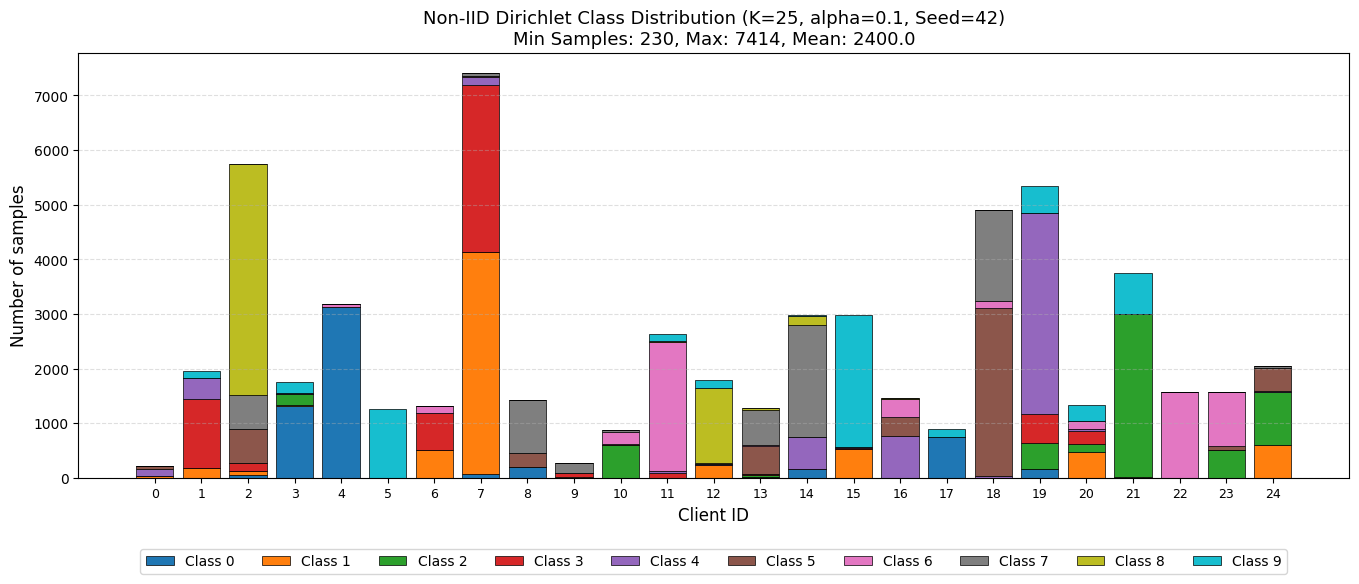

Partition chart saved to: /content/drive/MyDrive/FLasIRL(new)/data/mnist/partitions/Dirichlet/partition_dirichlet_alpha0.1_25_clients_seed42.png


In [13]:
def generate_dirichlet_partition(labels, num_clients=25, alpha=0.5, seed=42, min_samples=10, max_retries=100):
    labels_np = labels.cpu().numpy()
    num_samples = len(labels_np)
    classes = np.unique(labels_np)
    num_classes = len(classes)

    current_seed = seed
    for attempt in range(max_retries):
        rng = np.random.default_rng(current_seed)
        client_sample_indices = [[] for _ in range(num_clients)]

        for c in classes:
            idx_c = np.where(labels_np == c)[0]
            rng.shuffle(idx_c)
            proportions = rng.dirichlet(np.repeat(alpha, num_clients))
            counts = rng.multinomial(len(idx_c), proportions)

            start = 0
            for client_id, count in enumerate(counts):
                if count > 0:
                    client_sample_indices[client_id].extend(idx_c[start : start + count])
                    start += count

        client_sizes = [len(indices) for indices in client_sample_indices]
        if min(client_sizes) >= min_samples:
            client_indices = []
            client_class_counts = torch.zeros((num_clients, num_classes), dtype=torch.long)

            for client_id, indices in enumerate(client_sample_indices):
                indices_arr = np.array(indices, dtype=np.int64)
                rng.shuffle(indices_arr)
                t_indices = torch.tensor(indices_arr, dtype=torch.long)
                client_indices.append(t_indices)
                client_class_counts[client_id] = torch.bincount(labels[t_indices], minlength=num_classes)

            assert sum(len(x) for x in client_indices) == num_samples
            assert len(torch.cat(client_indices).unique()) == num_samples
            return client_indices, client_class_counts
        current_seed += 1

    raise RuntimeError(f'Could not generate Dirichlet partition with alpha={alpha} after {max_retries} attempts.')

partition_filename = f'dirichlet_alpha{DIRICHLET_ALPHA}_{NUM_CLIENTS}_seed{PARTITION_SEED}.pt'
partition_path = PARTITION_DIR / partition_filename

if partition_path.exists():
    print(f'Loading existing Dirichlet partition from {partition_path}...')
    partition = torch.load(partition_path, map_location='cpu')
    client_indices = partition['client_indices']
    if 'class_counts' in partition:
        client_class_counts = partition['class_counts']
    else:
        client_class_counts = torch.zeros(NUM_CLIENTS, 10, dtype=torch.long)
        for client_id, indices in enumerate(client_indices):
            client_class_counts[client_id] = torch.bincount(train_labels[indices], minlength=10)
else:
    print(f'Generating new Dirichlet partition (alpha={DIRICHLET_ALPHA}, clients={NUM_CLIENTS}, seed={PARTITION_SEED})...')
    client_indices, client_class_counts = generate_dirichlet_partition(
        train_labels, num_clients=NUM_CLIENTS, alpha=DIRICHLET_ALPHA, seed=PARTITION_SEED, min_samples=MIN_SAMPLES
    )
    payload = {
        'client_indices': client_indices,
        'seed': PARTITION_SEED,
        'num_clients': NUM_CLIENTS,
        'alpha': DIRICHLET_ALPHA,
        'distribution': 'dirichlet',
        'min_samples': MIN_SAMPLES,
        'class_counts': client_class_counts,
        'client_sizes': [len(x) for x in client_indices],
    }
    torch.save(payload, partition_path)
    print(f'Saved Dirichlet partition to {partition_path}')

assert sum(len(x) for x in client_indices) == len(train_labels)
assert len(torch.cat(client_indices).unique()) == len(train_labels)

client_sizes = np.array([len(x) for x in client_indices])
print(f'Client sizes: min={client_sizes.min()}, max={client_sizes.max()}, mean={client_sizes.mean():.1f}, std={client_sizes.std():.1f}')

# Plot Non-IID Dirichlet class distribution
plt.figure(figsize=(14, 6))
bottom = np.zeros(NUM_CLIENTS)
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for cls in range(10):
    values = client_class_counts[:, cls].cpu().numpy()
    plt.bar(
        np.arange(NUM_CLIENTS), values, bottom=bottom, label=f'Class {cls}',
        color=colors[cls], edgecolor='black', linewidth=0.5
    )
    bottom += values

plt.xlabel('Client ID', fontsize=12)
plt.ylabel('Number of samples', fontsize=12)
plt.title(
    f'Non-IID Dirichlet Class Distribution (K={NUM_CLIENTS}, alpha={DIRICHLET_ALPHA}, Seed={PARTITION_SEED})\n'
    f'Min Samples: {client_sizes.min()}, Max: {client_sizes.max()}, Mean: {client_sizes.mean():.1f}',
    fontsize=13
)
plt.xticks(np.arange(NUM_CLIENTS), labels=[str(i) for i in range(NUM_CLIENTS)], fontsize=9)
plt.legend(ncol=10, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

partition_chart = PARTITION_DIR / f'partition_dirichlet_alpha{DIRICHLET_ALPHA}_{NUM_CLIENTS}_clients_seed{PARTITION_SEED}.png'
plt.savefig(partition_chart, dpi=150, bbox_inches='tight')
plt.show()
print('Partition chart saved to:', partition_chart)


In [14]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class LinearProbe(nn.Module):
    def __init__(self, embedding_dim=512):
        super().__init__()
        self.linear = nn.Linear(embedding_dim, 10)

    def forward(self, x):
        return self.linear(x)


class RawLogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(28 * 28, 10)

    def forward(self, x):
        return self.linear(x)


def embedding_cache_filename(split):
    key = f'resnet18_imagenet1k_v1_resize{RESNET_SIZE}_imagenet_norm_{split}'
    h = hashlib.sha256(key.encode()).hexdigest()[:8]
    return f'resnet18_sz{RESNET_SIZE}_{split}_{h}.pt'


def preprocess_resnet(images):
    x = images.unsqueeze(1)
    x = F.interpolate(x, size=(RESNET_SIZE, RESNET_SIZE), mode='bilinear', align_corners=False)
    x = x.repeat(1, 3, 1, 1)
    return (x - IMAGENET_MEAN) / IMAGENET_STD


def make_embeddings(images, backbone):
    backbone.eval()
    output = []
    with torch.no_grad():
        for start in range(0, len(images), EMBED_BATCH_SIZE):
            batch = preprocess_resnet(images[start:start + EMBED_BATCH_SIZE].to(DEVICE))
            output.append(backbone(batch).float().cpu())
    return torch.cat(output)


if MODEL_NAME == 'resnet_linear':
    train_embed_path = DATA_DIR / embedding_cache_filename('train')
    test_embed_path = DATA_DIR / embedding_cache_filename('test')
    if train_embed_path.exists() and test_embed_path.exists():
        train_features = torch.load(train_embed_path, map_location='cpu')
        test_features = torch.load(test_embed_path, map_location='cpu')
    else:
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        backbone = models.resnet18(weights=weights).to(DEVICE)
        backbone.fc = nn.Identity()
        for parameter in backbone.parameters():
            parameter.requires_grad_(False)
        train_features = make_embeddings(train_images, backbone)
        test_features = make_embeddings(test_images, backbone)
        torch.save(train_features, train_embed_path)
        torch.save(test_features, test_embed_path)
        del backbone
        torch.cuda.empty_cache()
    train_features = train_features.to(DEVICE)
    test_features = test_features.to(DEVICE)
    print('Cached embeddings:', train_features.shape, test_features.shape)


def build_model():
    if MODEL_NAME == 'cnn':
        model = SmallCNN()
    elif MODEL_NAME == 'logreg_raw':
        model = RawLogisticRegression()
    else:
        model = LinearProbe(512)
    return model.to(DEVICE)

seed_everything(MODEL_SEED)
global_model = build_model()
print(global_model)


RawLogisticRegression(
  (linear): Linear(in_features=784, out_features=10, bias=True)
)


In [15]:
def batch_seed(round_id, client_id, local_epoch):
    return BATCH_SEED + round_id * 1_000_000 + client_id * 1_000 + local_epoch


def local_train(model, global_state, client_id, round_id):
    model.load_state_dict(global_state)
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
    indices = client_indices[client_id]
    for local_epoch in range(LOCAL_EPOCHS):
        generator = torch.Generator(device='cpu').manual_seed(batch_seed(round_id, client_id, local_epoch))
        permutation = indices[torch.randperm(len(indices), generator=generator)].to(DEVICE)
        for start in range(0, len(permutation), BATCH_SIZE):
            batch_indices = permutation[start:start + BATCH_SIZE]
            logits = model(train_features[batch_indices])
            loss = F.cross_entropy(logits, train_labels_gpu[batch_indices])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
    return {name: parameter.detach().clone() for name, parameter in model.named_parameters()}, len(indices)


@torch.no_grad()
def fedavg(client_states, client_sizes):
    total = float(sum(client_sizes))
    result = {}
    for name in client_states[0]:
        result[name] = sum(state[name] * (size / total) for state, size in zip(client_states, client_sizes))
    return result


@torch.no_grad()
def evaluate(model, features, labels):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    for start in range(0, len(labels), EVAL_BATCH_SIZE):
        x = features[start:start + EVAL_BATCH_SIZE]
        y = labels[start:start + EVAL_BATCH_SIZE]
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction='sum').item()
        total_correct += (logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(labels), total_correct / len(labels)


METRIC_FIELDS = ['round', 'global_train_loss', 'global_train_accuracy', 'test_loss', 'test_accuracy', 'learning_rate', 'num_clients', 'num_samples']


def load_metrics():
    if not METRICS_PATH.exists():
        return []
    with METRICS_PATH.open(newline='') as handle:
        return list(csv.DictReader(handle))


def truncate_metrics(round_id):
    rows = [row for row in load_metrics() if int(row['round']) <= round_id]
    tmp_path = METRICS_PATH.with_suffix('.tmp')
    with tmp_path.open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=METRIC_FIELDS)
        writer.writeheader()
        writer.writerows(rows)
    os.replace(tmp_path, METRICS_PATH)


def append_metric(row):
    exists = METRICS_PATH.exists()
    with METRICS_PATH.open('a', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=METRIC_FIELDS)
        if not exists:
            writer.writeheader()
        writer.writerow(row)
        handle.flush()
        os.fsync(handle.fileno())


def save_checkpoint(round_id, model):
    checkpoint = {
        'round': round_id,
        'model_state': {name: value.detach().cpu() for name, value in model.named_parameters()},
        'dirichlet_alpha': DIRICHLET_ALPHA,
        'partition_seed': PARTITION_SEED,
        'model_seed': MODEL_SEED,
        'batch_seed': BATCH_SEED,
        'config': {
            'model_name': MODEL_NAME, 'num_clients': NUM_CLIENTS, 'dirichlet_alpha': DIRICHLET_ALPHA,
            'local_epochs': LOCAL_EPOCHS, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE
        },
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state': torch.cuda.get_rng_state_all(),
    }
    tmp_path = CHECKPOINT_PATH.with_suffix('.pt.tmp')
    torch.save(checkpoint, tmp_path)
    os.replace(tmp_path, CHECKPOINT_PATH)


current_config = {
    'model_name': MODEL_NAME,
    'num_clients': NUM_CLIENTS,
    'local_epochs': LOCAL_EPOCHS,
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'resnet_size': RESNET_SIZE,
    'dirichlet_alpha': DIRICHLET_ALPHA,
    'partition_seed': PARTITION_SEED,
    'model_seed': MODEL_SEED,
    'batch_seed': BATCH_SEED,
}

start_round = 1
if CHECKPOINT_PATH.exists():
    if CONFIG_PATH.exists():
        with CONFIG_PATH.open('r') as handle:
            saved_config = json.load(handle)
        mismatches = []
        for key, current_val in current_config.items():
            if key in saved_config and saved_config[key] != current_val:
                mismatches.append(f"  - {key}: đã lưu = {saved_config[key]}, hiện tại = {current_val}")
        if mismatches:
            next_id = RUN_ID + 1 if isinstance(RUN_ID, int) else f"{RUN_ID}_new"
            raise ValueError(
                f"Lỗi: Cấu hình của Run {RUN_ID} đã bị thay đổi so với lần chạy trước!\n"
                f"Các thông số không khớp:\n" + "\n".join(mismatches) + "\n"
                f"-> Nếu muốn thử nghiệm cấu hình mới, hãy đổi sang RUN_ID mới (ví dụ: RUN_ID={next_id})."
            )
        saved_config['rounds'] = ROUNDS
        with CONFIG_PATH.open('w') as handle:
            json.dump(saved_config, handle, indent=2)

    checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
    global_model.load_state_dict(checkpoint['model_state'], strict=True)
    torch.set_rng_state(checkpoint['torch_rng_state'])
    torch.cuda.set_rng_state_all(checkpoint['cuda_rng_state'])
    completed_round = checkpoint['round']
    truncate_metrics(completed_round)
    start_round = completed_round + 1
    if start_round > ROUNDS:
        print(f"Run {RUN_ID} đã hoàn thành toàn bộ {completed_round} rounds (ROUNDS hiện tại = {ROUNDS}). Hãy tăng ROUNDS nếu muốn train tiếp.")
    else:
        print(f"Phát hiện checkpoint của Run {RUN_ID} (round {completed_round}). Đang tiếp tục huấn luyện đến round {ROUNDS}...")
else:
    full_config = {
        'run_id': RUN_ID,
        'run_dir': str(RUN_DIR),
        'rounds': ROUNDS,
        **current_config,
        'partition_path': str(partition_path),
        'device': str(DEVICE),
    }
    with CONFIG_PATH.open('w') as handle:
        json.dump(full_config, handle, indent=2)
    print(f"Bắt đầu Run {RUN_ID} mới từ round 1 đến {ROUNDS}...")

# Single local model reused across clients to reduce allocation churn
worker_model = build_model()

for round_id in range(start_round, ROUNDS + 1):
    round_start = time.time()
    global_state = {name: parameter.detach().clone() for name, parameter in global_model.named_parameters()}
    client_states, client_sizes = [], []
    for client_id in range(NUM_CLIENTS):
        state, size = local_train(worker_model, global_state, client_id, round_id)
        client_states.append(state)
        client_sizes.append(size)
    global_model.load_state_dict(fedavg(client_states, client_sizes), strict=True)
    global_train_loss, global_train_accuracy = evaluate(global_model, train_features, train_labels_gpu)
    test_loss, test_accuracy = evaluate(global_model, test_features, test_labels_gpu)
    row = {
        'round': round_id,
        'global_train_loss': global_train_loss,
        'global_train_accuracy': global_train_accuracy,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'learning_rate': LEARNING_RATE,
        'num_clients': NUM_CLIENTS,
        'num_samples': sum(client_sizes)
    }
    append_metric(row)
    save_checkpoint(round_id, global_model)
    print(f'Round {round_id:02d}/{ROUNDS} | train loss {global_train_loss:.4f} (acc {global_train_accuracy:.2%}) | test loss {test_loss:.4f} (acc {test_accuracy:.2%}) | {time.time() - round_start:.1f}s')

del worker_model
torch.save({name: value.detach().cpu() for name, value in global_model.named_parameters()}, RUN_DIR / 'final_model_parameters.pt')
print('Finished. Results:', RUN_DIR)


Bắt đầu Run 4 mới từ round 1 đến 100...
Round 01/100 | train loss 1.3170 (acc 66.22%) | test loss 1.3060 (acc 66.90%) | 2.3s
Round 02/100 | train loss 0.9612 (acc 74.23%) | test loss 0.9480 (acc 75.00%) | 2.3s
Round 03/100 | train loss 0.7865 (acc 78.65%) | test loss 0.7724 (acc 79.06%) | 2.2s
Round 04/100 | train loss 0.6843 (acc 81.16%) | test loss 0.6702 (acc 81.75%) | 2.2s
Round 05/100 | train loss 0.6193 (acc 82.89%) | test loss 0.6051 (acc 83.47%) | 2.3s
Round 06/100 | train loss 0.5733 (acc 84.10%) | test loss 0.5596 (acc 84.80%) | 2.3s
Round 07/100 | train loss 0.5411 (acc 84.89%) | test loss 0.5278 (acc 85.35%) | 2.3s
Round 08/100 | train loss 0.5166 (acc 85.51%) | test loss 0.5036 (acc 85.86%) | 2.3s
Round 09/100 | train loss 0.4973 (acc 85.95%) | test loss 0.4851 (acc 86.16%) | 2.2s
Round 10/100 | train loss 0.4815 (acc 86.32%) | test loss 0.4700 (acc 86.46%) | 2.2s
Round 11/100 | train loss 0.4685 (acc 86.61%) | test loss 0.4574 (acc 86.91%) | 2.3s
Round 12/100 | train loss

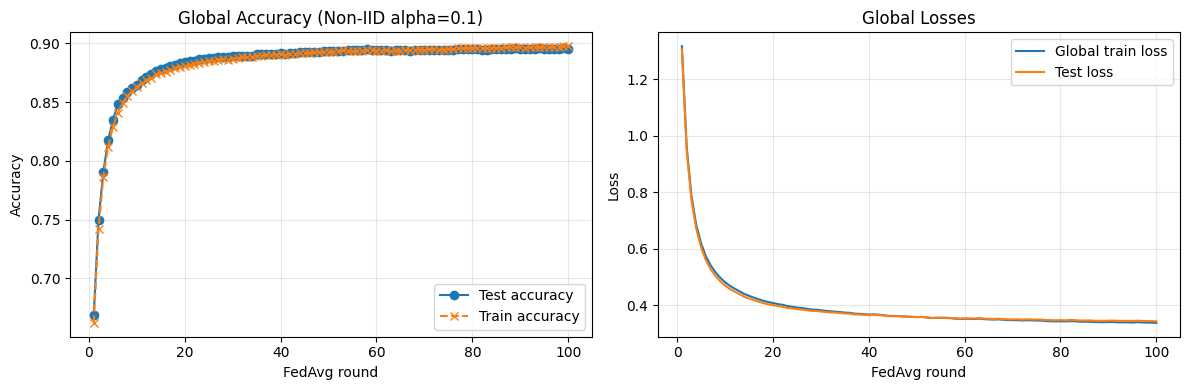

Final test accuracy (primary): 0.8956
Best test accuracy (secondary diagnostic): 0.896
Summary saved to: /content/drive/MyDrive/FLasIRL(new)/fedavg_noniid/run4/summary.json


In [16]:
# Load and plot a completed or partially completed run
plot_run_id = RUN_ID  # e.g. 1, 'run1', or set to an existing run ID
plot_run_dir = RUN_DIR if plot_run_id == RUN_ID else EXP_DIR / (str(plot_run_id) if str(plot_run_id).startswith('run') else f'run{plot_run_id}')
plot_metrics_path = plot_run_dir / 'metrics.csv'

if not plot_metrics_path.exists():
    print(f'No metrics found at {plot_metrics_path}')
else:
    with plot_metrics_path.open(newline='') as handle:
        rows = list(csv.DictReader(handle))
    if not rows:
        print('Metrics file is empty.')
    else:
        rounds = [int(row['round']) for row in rows]
        accuracy = [float(row['test_accuracy']) for row in rows]
        train_accuracy = [float(row['global_train_accuracy']) for row in rows] if 'global_train_accuracy' in rows[0] else None
        train_loss = [float(row['global_train_loss']) for row in rows]
        test_loss = [float(row['test_loss']) for row in rows]

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(rounds, accuracy, marker='o', label='Test accuracy')
        if train_accuracy:
            axes[0].plot(rounds, train_accuracy, marker='x', linestyle='--', label='Train accuracy')
            axes[0].legend()
        axes[0].set(xlabel='FedAvg round', ylabel='Accuracy', title=f'Global Accuracy (Non-IID alpha={DIRICHLET_ALPHA})')
        axes[0].grid(True, alpha=0.3)

        axes[1].plot(rounds, train_loss, label='Global train loss')
        axes[1].plot(rounds, test_loss, label='Test loss')
        axes[1].set(xlabel='FedAvg round', ylabel='Loss', title='Global Losses')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        plt.tight_layout()

        result_chart = plot_run_dir / 'metrics.png'
        plt.savefig(result_chart, dpi=150)
        plt.show()

        summary = {
            'run_id': plot_run_id,
            'run_dir': str(plot_run_dir),
            'model_name': MODEL_NAME,
            'dirichlet_alpha': DIRICHLET_ALPHA,
            'completed_rounds': len(rounds),
            'final_test_accuracy': accuracy[-1],
            'best_test_accuracy': max(accuracy),
            'final_train_loss': train_loss[-1],
            'final_test_loss': test_loss[-1],
        }
        if train_accuracy:
            summary['final_train_accuracy'] = train_accuracy[-1]

        summary_path = plot_run_dir / 'summary.json'
        with summary_path.open('w') as handle:
            json.dump(summary, handle, indent=2)

        print('Final test accuracy (primary):', accuracy[-1])
        print('Best test accuracy (secondary diagnostic):', max(accuracy))
        print('Summary saved to:', summary_path)
